## Making Audrey's station list match the production ShakeAlert station list as closely as possible
#### Need to remove some stations that were never installed
#### Need to fill in some "new" stations with the closest BGRID location 

In [1]:
# Are we keeping the offshore stations in or not?
keep_offshore = True

# Can we use pygmt? If no, False. Skips those cells.
use_pygmt = False

# Working directory
path = '/Users/sydneydybing/pnw_working/M9_sims/new/'

In [2]:
from obspy.core import read, Stream, Trace
from obspy.signal.filter import lowpass
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopy.distance import great_circle, geodesic
import warnings
if use_pygmt:
    import pygmt
warnings.simplefilter(action = 'ignore', category = FutureWarning)
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.

Read in ShakeAlert production list

In [3]:
# ShakeAlert production station locations, as of May 2025
column_names = ['network','station','location','channel','latitude','longitude','elevation']
prodchans = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/location/tt_grids/ShakeAlert_chanfile_all_noCondSusp_20250506.dat', header = 23, delim_whitespace = True, usecols = [0,1,2,3,4,5,6], comment = '#', names = column_names)

# Additionally - list of Canadian stations that are being tested, from Mouse!
futcanchans = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/location/tt_grids/20250425-chanfile_local_Canada_2025-04-25.dat', header = 23, delim_whitespace = True, usecols = [0,1,2,3,4,5,6], comment = '#', names = column_names)

# Also, list of new stations since May 2025 or that will be added soon, also from Mouse!
futpnsnchans = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/location/tt_grids/new_stas_since_may25_mouse.csv', names = ['net', 'sta', 'lat', 'lon'])

In [4]:
futpnsnchans

,net,sta,lat,lon
0,UO,SUGAR,43.117240,-121.607850
1,UO,CRESC,43.462495,-121.668335
2,UO,JODA,44.440680,-118.419890
3,UO,CHUTE,43.802011,-121.696563
4,UW,OIL,47.769660,-124.408590
5,UW,LKCAV,48.309650,-121.987410
6,UW,LAVA,45.458360,-121.624340
7,UW,ODEER,47.949260,-123.265210
8,UW,MNRL,46.651270,-122.330410
9,UW,BURLY,46.407500,-121.866250


In [5]:
# Process production stations

# Remove any name duplicates
prod_names = [prodchans.iloc[i].network + '.' + prodchans.iloc[i].station for i in range(len(prodchans))]
scr, unique_ind = np.unique(prod_names, return_index = True)
prodstas = prodchans.iloc[unique_ind].reset_index(drop = True)

# Remove any exact location duplicates
locs = [(prodstas.iloc[i].longitude, prodstas.iloc[i].latitude) for i in range(len(prodstas))]
scr, unique_ind = np.unique(locs, axis = 0, return_index = True)
prodstas = prodstas.iloc[unique_ind].reset_index(drop = True)

# Trim to simulation area
prodstas = prodstas[prodstas['latitude'] > 40]
prodstas = prodstas[prodstas['latitude'] < 50.7]
prodstas = prodstas[prodstas['longitude'] < -120.3]
prodstas = prodstas.reset_index(drop = True)

In [6]:
# Process new PNSN stations

# Remove any name duplicates
futpnsn_names = [futpnsnchans.iloc[i].net + '.' + futpnsnchans.iloc[i].sta for i in range(len(futpnsnchans))]
scr, unique_ind = np.unique(futpnsn_names, return_index=True)
futpnsnstas = futpnsnchans.iloc[unique_ind].reset_index(drop = True)

# Remove any exact location duplicates
locs = [(futpnsnstas.iloc[i].lon, futpnsnstas.iloc[i].lat) for i in range(len(futpnsnstas))]
scr, unique_ind = np.unique(locs, axis = 0, return_index = True)
futpnsnstas = futpnsnstas.iloc[unique_ind].reset_index(drop = True)

# Trim to simulation area
futpnsnstas = futpnsnstas[futpnsnstas['lat'] > 40]
futpnsnstas = futpnsnstas[futpnsnstas['lat'] < 50.7]
futpnsnstas = futpnsnstas[futpnsnstas['lon'] < -120.3]
futpnsnstas = futpnsnstas.reset_index(drop = True)

# Reformat to match prodstas formatting
futpnsnstasfmt = pd.DataFrame({
    "network": futpnsnstas["net"],
    "station": futpnsnstas["sta"],
    "location": "--",       # fill with default
    "channel": "HHE",       # fill with default
    "latitude": futpnsnstas["lat"],
    "longitude": futpnsnstas["lon"],
    "elevation": 0          # fill with default
})

In [7]:
futpnsnstasfmt

,network,station,location,channel,latitude,longitude,elevation
0,UW,OIL,--,HHE,47.769660,-124.408590,0
1,UW,ODEER,--,HHE,47.949260,-123.265210,0
2,UW,MNRL,--,HHE,46.651270,-122.330410,0
3,UW,VLM,--,HHE,45.538340,-122.040360,0
4,UW,LKCAV,--,HHE,48.309650,-121.987410,0
5,UW,BURLY,--,HHE,46.407500,-121.866250,0
6,UO,CHUTE,--,HHE,43.802011,-121.696563,0
7,UO,CRESC,--,HHE,43.462495,-121.668335,0
8,UW,LAVA,--,HHE,45.458360,-121.624340,0
9,UO,SUGAR,--,HHE,43.117240,-121.607850,0


In [8]:
# Any overlaps of new PNSN stas with the production list? No

if use_pygmt:

    fig = pygmt.Figure()
        
    min_lon = -129
    max_lon = -120
    min_lat = 40
    max_lat = 51
    region = [min_lon-1, max_lon+2, min_lat-0.5, max_lat+0.25]
    fig.coast(region = region, projection = 'N12c', land = 'wheat3', water = 'lightcyan2', frame = ['afg']) # Coastline
    fig.plot(x = prodstas.longitude, y = prodstas.latitude, style = 't0.4c', fill = 'white', pen = '0.5p,black', label = 'Prod')
    fig.plot(x = futpnsnstas.lon, y = futpnsnstas.lat, style = 't0.2c', fill = 'navy', pen = '0.5p,black', label = 'New PNSN')
    
    # fig.text(text = prodCN.station, x = prodCN.longitude.astype(float), y = prodCN.latitude.astype(float)-0.1, font = '7p,Helvetica,black')
    
    fig.legend()
    fig.show(dpi = 500, width = 500)

In [9]:
# Process Canadian stations

# Remove any name duplicates
can_names = [futcanchans.iloc[i].network + '.' + futcanchans.iloc[i].station for i in range(len(futcanchans))]
scr, unique_ind = np.unique(can_names, return_index=True)
futcanstas = futcanchans.iloc[unique_ind].reset_index(drop = True)

# Remove any exact location duplicates
locs = [(futcanstas.iloc[i].longitude, futcanstas.iloc[i].latitude) for i in range(len(futcanstas))]
scr, unique_ind = np.unique(locs, axis = 0, return_index = True)
futcanstas = futcanstas.iloc[unique_ind].reset_index(drop = True)

# Trim to simulation area
futcanstas = futcanstas[futcanstas['latitude'] > 40]
futcanstas = futcanstas[futcanstas['latitude'] < 50.7]
futcanstas = futcanstas[futcanstas['longitude'] < -120.3]
futcanstas = futcanstas.reset_index(drop = True)

In [10]:
canQX = futcanstas.loc[futcanstas['network'] == 'QX']
canQW = futcanstas.loc[futcanstas['network'] == 'QW']
canCN = futcanstas.loc[futcanstas['network'] == 'CN']

prodQX = prodstas.loc[prodstas['network'] == 'QX'] # empty
prodQW = prodstas.loc[prodstas['network'] == 'QW'] # empty
prodCN = prodstas.loc[prodstas['network'] == 'CN'] # 2 of the same as canCN (WOSB and WSLR)

if use_pygmt:

    ### CN network origins ###
    
    fig = pygmt.Figure()
    
    min_lon = -129
    max_lon = -120
    min_lat = 48
    max_lat = 51
    region = [min_lon-1, max_lon+2, min_lat-0.5, max_lat+0.25]
    fig.coast(region = region, projection = 'N12c', land = 'wheat3', water = 'lightcyan2', frame = ['afg']) # Coastline
    fig.plot(x = canCN.longitude, y = canCN.latitude, style = 't0.4c', fill = 'white', pen = '0.5p,black', label = 'canCN')
    fig.plot(x = prodCN.longitude, y = prodCN.latitude, style = 't0.2c', fill = 'navy', pen = '0.5p,black', label = 'prodCN')

    fig.text(text = prodCN.station, x = prodCN.longitude.astype(float), y = prodCN.latitude.astype(float)-0.1, font = '7p,Helvetica,black')

    fig.legend()
    fig.show(dpi = 500, width = 900)

In [11]:
# Combine them into one DataFrame - simulation "production" station set

prod_sim_stas = pd.concat([prodstas, futcanstas], ignore_index = True)
prod_sim_stas

# Toss duplicates between Canada and production lists that have different names and slightly different locations (12 stations)
# Keeping ones with Canadian naming scheme, and keeping both instruments of WOSB and WSLR

can_dup_idxs = []
prod_dup_idxs = []

for f in range(len(futcanstas)):
    can_name = futcanstas.station[f]
    can_lon = futcanstas.longitude[f].astype(float)
    can_lat = futcanstas.latitude[f].astype(float)

    prod_names = prodstas.station.values
    prod_lons = prodstas.longitude.values.astype(float)
    prod_lats = prodstas.latitude.values.astype(float)

    atol = 0.005
        
    g = np.where((np.abs(prod_lons - can_lon) < atol) & (np.abs(prod_lats - can_lat) < atol))[0]
    if len(g) == 1:
        can_dup_idxs.append(f)
        prod_dup_idxs.append(g[0])
    elif len(g) > 1:
        print(can_name + ' has multiple production dups!')

overlaps_can = futcanstas.iloc[can_dup_idxs].reset_index(drop = True)
overlaps_prod = prodstas.iloc[prod_dup_idxs].reset_index(drop = True)

# We want to keep both instruments of WOSB and WSLR, so exclude those from the overlap lists
canWs = overlaps_can.loc[overlaps_can['station'].isin(['WOSB', 'WSLR'])].index
candropped = overlaps_can.drop(index = canWs).reset_index(drop = True)
overlaps_can = candropped

prodWs = overlaps_prod.loc[overlaps_prod['station'].isin(['WOSB', 'WSLR'])].index
proddropped = overlaps_prod.drop(index = prodWs).reset_index(drop = True)
overlaps_prod = proddropped
# overlaps_prod

# Get the indices for the rows in the full station list that have the duplicated stations with the production names

prodsim_idxs_to_remove = []
for p in range(len(prod_sim_stas)):
    prodsim_netstachan = prod_sim_stas.network[p] + '.' + prod_sim_stas.station[p] + '.' + prod_sim_stas.channel[p]
    for r in range(len(overlaps_prod)):
        overlapprod_netstachan = overlaps_prod.network[r] + '.' + overlaps_prod.station[r] + '.' + overlaps_prod.channel[r]
        if overlapprod_netstachan == prodsim_netstachan:
            # print(prodsim_netstachan)
            prodsim_idxs_to_remove.append(p)
print(len(prodsim_idxs_to_remove))

# Drop the rows
dropped = prod_sim_stas.drop(index = prodsim_idxs_to_remove).reset_index(drop = True)

# Add the new PNSN stations
added_new_pnsn = pd.concat([dropped, futpnsnstasfmt], ignore_index = True)

# Organize
prod_sim_stas = added_new_pnsn.sort_values(by = ['network', 'station']).reset_index(drop = True)
prod_sim_stas
# prod_sim_stas.loc[prod_sim_stas['station'].isin(['WOSB', 'WSLR'])]

12


,network,station,location,channel,latitude,longitude,elevation
0,BK,BAKR,00,HHE,40.2804,-122.4923,190.1
1,BK,BIGM,00,HHE,40.8865,-123.3621,1068.5
2,BK,BIGV,00,HHE,41.0944,-121.2277,1484.4
3,BK,BJES,00,HHE,40.5436,-123.8800,1047.4
4,BK,BLAS,00,HHE,40.3227,-123.5325,1678.0
...,...,...,...,...,...,...,...
695,UW,WYNO,--,ENE,47.4339,-123.6130,935.4
696,UW,YACH,--,HNE,44.3150,-124.0966,217.0
697,UW,YACT,--,ENE,45.9325,-122.4193,211.2
698,UW,YELM,--,ENE,46.9402,-122.5908,102.9


In [12]:
QX = prod_sim_stas.loc[prod_sim_stas['network'] == 'QX']
QW = prod_sim_stas.loc[prod_sim_stas['network'] == 'QW']
CN = prod_sim_stas.loc[prod_sim_stas['network'] == 'CN']

Read in Audrey's "PNSN" grid, from one of the scenario information csvs (can be any of them)

In [13]:
### Audrey's PNSN station locations ###

audrey_pnsn_stas = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/replays/audrey_broadband_pnsngrid/PNSN_IM_buried-random-mur13-shallow.csv')
# There are a few location duplicates in here. Catch and toss those
locs = [(audrey_pnsn_stas.iloc[i].lon, audrey_pnsn_stas.iloc[i].lat) for i in range(len(audrey_pnsn_stas))]
scr, unique_ind = np.unique(locs, axis = 0, return_index = True)
audrey_pnsn_stas = audrey_pnsn_stas.iloc[unique_ind].reset_index(drop = True)

audrey_pnsn_stas_lon = [audrey_pnsn_stas.iloc[i].lon for i in range(len(audrey_pnsn_stas))]
audrey_pnsn_stas_lat = [audrey_pnsn_stas.iloc[i].lat for i in range(len(audrey_pnsn_stas))]

audrey_pnsn_stas

,stn,lon,lat,rrup(km),PGA_x(g),PGA_y(g),PGV_x(m/s),PGV_y(m/s),PGD_x(m),PGD_y(m),...,SA_0p5s(g),SA_0p75s(g),SA_1p0s(g),SA_1p5s(g),SA_2p0s(g),SA_3p0s(g),SA_4p0s(g),SA_5p0s(g),SA_7p5s(g),SA_10p0s(g)
0,NC27,-127.758,47.763,99.162,0.074854,0.072848,0.141,0.199,0.261,0.419,...,0.1792,0.1187,0.0629,0.0538,0.0403,0.0352,0.0209,0.0132,0.0131,0.0228
1,CBC27,-127.732,47.757,97.811,0.081591,0.096550,0.128,0.201,0.256,0.418,...,0.1891,0.1412,0.0621,0.0514,0.0405,0.0342,0.0211,0.0132,0.0126,0.0223
2,PACB,-127.492,50.436,99.556,0.059297,0.070730,0.296,0.390,0.611,0.672,...,0.1204,0.1034,0.1499,0.1320,0.0754,0.0482,0.0435,0.0469,0.0588,0.0328
3,CQS64,-126.873,48.700,6.655,0.775054,0.799719,2.071,2.518,5.653,6.716,...,1.2365,0.6972,0.7936,0.5622,0.3940,0.4449,0.4199,0.3681,0.2757,0.1427
4,NC89,-126.848,48.671,6.627,0.729580,0.652114,2.940,2.236,6.416,6.966,...,0.9322,0.8189,0.7204,0.7260,0.6240,0.4500,0.4233,0.3876,0.2818,0.1782
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1028,YA2,-120.531,46.527,296.247,0.027611,0.029676,0.083,0.152,0.222,0.326,...,0.0789,0.0499,0.0424,0.0428,0.0454,0.0302,0.0186,0.0169,0.0107,0.0145
1029,SLF,-120.529,47.761,286.984,0.024103,0.030310,0.046,0.115,0.112,0.209,...,0.0572,0.0427,0.0406,0.0428,0.0330,0.0227,0.0171,0.0131,0.0101,0.0094
1030,UGSD,-120.479,46.556,299.341,0.026462,0.028234,0.095,0.151,0.220,0.298,...,0.0589,0.0488,0.0486,0.0434,0.0447,0.0320,0.0203,0.0181,0.0091,0.0118
1031,UGP4,-120.446,46.530,302.453,0.022704,0.026266,0.086,0.142,0.214,0.289,...,0.0639,0.0501,0.0419,0.0459,0.0414,0.0326,0.0235,0.0164,0.0086,0.0116


In [14]:
# Why does Audrey have so many more? Loop through hers and if there isn't a matching location for a station in the production list, print out the row

### This cell finds the extra stations in the AUDREY station set that are not in the production list by location ###

aud_unmatched_idxs = []
mult_matches_aud_idxs = []
mult_matches_prod_idxs = []

for i in range(len(audrey_pnsn_stas)):
    
    aud_sta_name = audrey_pnsn_stas['stn'][i]
    aud_sta_lon = audrey_pnsn_stas['lon'][i].astype(float)
    aud_sta_lat = audrey_pnsn_stas['lat'][i].astype(float)

    prod_sim_stas_names = prod_sim_stas.station.values
    prod_sim_stas_lons = prod_sim_stas.longitude.values.astype(float)
    prod_sim_stas_lats = prod_sim_stas.latitude.values.astype(float)
    
    atol = 0.005 # lat/lon difference tolerance between Audrey and prod_sim station locations
        
    j = np.where((np.abs(prod_sim_stas_lons - aud_sta_lon) < atol) & (np.abs(prod_sim_stas_lats - aud_sta_lat) < atol))[0]
    if len(j) == 0:
        aud_unmatched_idxs.append(i)
    elif len(j) > 1: # If an Audrey station has multiple possible matches in the prod_sim list, check if the name of the Audrey station is in that list. If not, note it.
        if aud_sta_name in prod_sim_stas_names[j]:
            pass
        else:
            print('Audrey station:')
            print(aud_sta_name, aud_sta_lat, aud_sta_lon)
            print('Matching production stations:')
            print(prod_sim_stas_names[j], prod_sim_stas_lons[j], prod_sim_stas_lats[j])
            print('')
            mult_matches_aud_idxs.append(i)
            mult_matches_prod_idxs.append(j)

offshore_stas = ['HYSB1', 'HYS14', 'BACME', 'CBC27', 'CQS64', 'NC89', 'NCBC', 'NC27']
offshore_sta_idxs = list(audrey_pnsn_stas.loc[audrey_pnsn_stas['stn'].isin(offshore_stas)].index)

if keep_offshore:
    aud_unmatched_idxs = np.setdiff1d(aud_unmatched_idxs, offshore_sta_idxs)

print(str(len(aud_unmatched_idxs)) + ' stations in Audrey PNSN list that are NOT in the prod_sim list. Need to be removed.')
if len(mult_matches_aud_idxs) > 0 or len(mult_matches_prod_idxs) > 0:
    print('Some stations had multiple matches but the names did not line up! Check me!')

382 stations in Audrey PNSN list that are NOT in the prod_sim list. Need to be removed.


In [15]:
# Make initial keepers and removers dfs

audrey_stas_to_remove_initial = audrey_pnsn_stas.iloc[aud_unmatched_idxs].reset_index(drop = True)
audrey_stas_to_keep_initial = audrey_pnsn_stas.drop(aud_unmatched_idxs).reset_index(drop = True)
audrey_stas_to_keep_initial

,stn,lon,lat,rrup(km),PGA_x(g),PGA_y(g),PGV_x(m/s),PGV_y(m/s),PGD_x(m),PGD_y(m),...,SA_0p5s(g),SA_0p75s(g),SA_1p0s(g),SA_1p5s(g),SA_2p0s(g),SA_3p0s(g),SA_4p0s(g),SA_5p0s(g),SA_7p5s(g),SA_10p0s(g)
0,NC27,-127.758,47.763,99.162,0.074854,0.072848,0.141,0.199,0.261,0.419,...,0.1792,0.1187,0.0629,0.0538,0.0403,0.0352,0.0209,0.0132,0.0131,0.0228
1,CBC27,-127.732,47.757,97.811,0.081591,0.096550,0.128,0.201,0.256,0.418,...,0.1891,0.1412,0.0621,0.0514,0.0405,0.0342,0.0211,0.0132,0.0126,0.0223
2,PACB,-127.492,50.436,99.556,0.059297,0.070730,0.296,0.390,0.611,0.672,...,0.1204,0.1034,0.1499,0.1320,0.0754,0.0482,0.0435,0.0469,0.0588,0.0328
3,CQS64,-126.873,48.700,6.655,0.775054,0.799719,2.071,2.518,5.653,6.716,...,1.2365,0.6972,0.7936,0.5622,0.3940,0.4449,0.4199,0.3681,0.2757,0.1427
4,NC89,-126.848,48.671,6.627,0.729580,0.652114,2.940,2.236,6.416,6.966,...,0.9322,0.8189,0.7204,0.7260,0.6240,0.4500,0.4233,0.3876,0.2818,0.1782
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
646,TBLMT,-120.598,47.173,280.928,0.028872,0.029876,0.067,0.144,0.165,0.343,...,0.0622,0.0585,0.0383,0.0394,0.0464,0.0274,0.0140,0.0130,0.0129,0.0101
647,RIMR,-120.593,41.821,319.887,0.017686,0.018118,0.099,0.111,0.220,0.230,...,0.0412,0.0411,0.0246,0.0184,0.0199,0.0219,0.0137,0.0145,0.0187,0.0206
648,SLF,-120.529,47.761,286.984,0.024103,0.030310,0.046,0.115,0.112,0.209,...,0.0572,0.0427,0.0406,0.0428,0.0330,0.0227,0.0171,0.0131,0.0101,0.0094
649,UGSD,-120.479,46.556,299.341,0.026462,0.028234,0.095,0.151,0.220,0.298,...,0.0589,0.0488,0.0486,0.0434,0.0447,0.0320,0.0203,0.0181,0.0091,0.0118


In [16]:
# What about stations that are really close in the Audrey keeper station list, but not exact location duplicates? Are they real?
# Loop through the keepers and check stations that are close to each one. If it's more than one (itself), print it to check IRIS MDA
# Does not catch loner stations that are no longer operating, 
# but those wouldn't be in the production list you'd think so those should already be set to remove based on that location comparison

for i in range(len(audrey_stas_to_keep_initial)):
    
    sta_name = audrey_stas_to_keep_initial['stn'][i]
    sta_lon = audrey_stas_to_keep_initial['lon'][i].astype(float)
    sta_lat = audrey_stas_to_keep_initial['lat'][i].astype(float)

    stas_names = audrey_stas_to_keep_initial.stn.values
    stas_lons = audrey_stas_to_keep_initial.lon.values.astype(float)
    stas_lats = audrey_stas_to_keep_initial.lat.values.astype(float)
    atol = 0.005
        
    j = np.where((np.abs(stas_lons - sta_lon) < atol) & (np.abs(stas_lats - sta_lat) < atol))[0]
    if len(j) > 1: # If a prod_sim station has multiple possible matches in the Audrey list, check if the name of the prod_sim station is in that list. If not, note it.
        print('Checking station:')
        print(sta_name, sta_lat, sta_lon)
        print('Nearby stations:')
        print(stas_names[j], stas_lons[j], stas_lats[j])
        print('')

# ETB stopped running in 2020 and should be removed
# ETPB is good
# BFSB, BAMF, and B928 are good
# B026 and ROBC are good
# LRIV, B005, B006, and B007 are good
# PGC, B009, and B010 are good
# PA12 and PA02 do not appear to have current stations and should be removed
# B011 is good
# MERL, B035, and B036 are good
# BOW ended in 2018 and should be removed
# BOW2 is good
# RVW ended in 2018 and should be removed
# RVW2 is good
# HUT1 and 7042 are good
# SCC ended in 2021 and should be removed
# SCC2 is good
# PNLK and PNLK2 are good
# TLW1 and TOLT are good
# VIP ended in 2018 and should be removed
# VIP2 is good
# TBM and TBLMT are good

# Custom removal of old stations that have others nearby: ETB, PA12, PA02, BOW, RVW, SCC, VIP

Checking station:
ETPB 49.383 -126.543
Nearby stations:
['ETPB' 'ETB'] [-126.543 -126.542] [49.383 49.383]

Checking station:
ETB 49.383 -126.542
Nearby stations:
['ETPB' 'ETB'] [-126.543 -126.542] [49.383 49.383]

Checking station:
BFSB 48.834 -125.136
Nearby stations:
['BFSB' 'BAMF' 'B928'] [-125.136 -125.135 -125.134] [48.834 48.835 48.834]

Checking station:
BAMF 48.835 -125.135
Nearby stations:
['BFSB' 'BAMF' 'B928'] [-125.136 -125.135 -125.134] [48.834 48.835 48.834]

Checking station:
B928 48.834 -125.134
Nearby stations:
['BFSB' 'BAMF' 'B928'] [-125.136 -125.135 -125.134] [48.834 48.835 48.834]

Checking station:
B026 45.309 -123.823
Nearby stations:
['B026' 'ROBC'] [-123.823 -123.823] [45.309 45.31 ]

Checking station:
ROBC 45.31 -123.823
Nearby stations:
['B026' 'ROBC'] [-123.823 -123.823] [45.309 45.31 ]

Checking station:
LRIV 48.057 -123.504
Nearby stations:
['LRIV' 'B007' 'B005' 'B006'] [-123.504 -123.504 -123.503 -123.501] [48.057 48.058 48.06  48.059]

Checking station:

In [17]:
# Remove these extra stations from the keeper list (and add to removal list)

### Makes final Audrey keeper and remover station lists ###

extra_removals = ['ETB', 'PA12', 'PA02', 'BOW', 'RVW', 'SCC', 'VIP']
extra_removals_idxs = np.array(audrey_pnsn_stas.loc[audrey_pnsn_stas['stn'].isin(extra_removals)].index)
removal_idxs = np.sort(np.append(aud_unmatched_idxs, extra_removals_idxs))

audrey_stas_to_remove = audrey_pnsn_stas.iloc[removal_idxs].reset_index(drop = True)
audrey_stas_to_keep = audrey_pnsn_stas.drop(removal_idxs).reset_index(drop = True)
audrey_stas_to_keep

,stn,lon,lat,rrup(km),PGA_x(g),PGA_y(g),PGV_x(m/s),PGV_y(m/s),PGD_x(m),PGD_y(m),...,SA_0p5s(g),SA_0p75s(g),SA_1p0s(g),SA_1p5s(g),SA_2p0s(g),SA_3p0s(g),SA_4p0s(g),SA_5p0s(g),SA_7p5s(g),SA_10p0s(g)
0,NC27,-127.758,47.763,99.162,0.074854,0.072848,0.141,0.199,0.261,0.419,...,0.1792,0.1187,0.0629,0.0538,0.0403,0.0352,0.0209,0.0132,0.0131,0.0228
1,CBC27,-127.732,47.757,97.811,0.081591,0.096550,0.128,0.201,0.256,0.418,...,0.1891,0.1412,0.0621,0.0514,0.0405,0.0342,0.0211,0.0132,0.0126,0.0223
2,PACB,-127.492,50.436,99.556,0.059297,0.070730,0.296,0.390,0.611,0.672,...,0.1204,0.1034,0.1499,0.1320,0.0754,0.0482,0.0435,0.0469,0.0588,0.0328
3,CQS64,-126.873,48.700,6.655,0.775054,0.799719,2.071,2.518,5.653,6.716,...,1.2365,0.6972,0.7936,0.5622,0.3940,0.4449,0.4199,0.3681,0.2757,0.1427
4,NC89,-126.848,48.671,6.627,0.729580,0.652114,2.940,2.236,6.416,6.966,...,0.9322,0.8189,0.7204,0.7260,0.6240,0.4500,0.4233,0.3876,0.2818,0.1782
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
639,TBLMT,-120.598,47.173,280.928,0.028872,0.029876,0.067,0.144,0.165,0.343,...,0.0622,0.0585,0.0383,0.0394,0.0464,0.0274,0.0140,0.0130,0.0129,0.0101
640,RIMR,-120.593,41.821,319.887,0.017686,0.018118,0.099,0.111,0.220,0.230,...,0.0412,0.0411,0.0246,0.0184,0.0199,0.0219,0.0137,0.0145,0.0187,0.0206
641,SLF,-120.529,47.761,286.984,0.024103,0.030310,0.046,0.115,0.112,0.209,...,0.0572,0.0427,0.0406,0.0428,0.0330,0.0227,0.0171,0.0131,0.0101,0.0094
642,UGSD,-120.479,46.556,299.341,0.026462,0.028234,0.095,0.151,0.220,0.298,...,0.0589,0.0488,0.0486,0.0434,0.0447,0.0320,0.0203,0.0181,0.0091,0.0118


In [18]:
### This cell finds the extra stations in the PROD_SIM station set that are not in the keeper Audrey station set. They'll need to be added from the BGRID. ###

prod_sim_unmatched_idxs = []
mult_matches_aud_idxs = []
mult_matches_prod_idxs = []

for i in range(len(prod_sim_stas)):
    
    prod_sta_name = prod_sim_stas['station'][i]
    prod_sta_lon = prod_sim_stas['longitude'][i].astype(float)
    prod_sta_lat = prod_sim_stas['latitude'][i].astype(float)

    aud_stas_names = audrey_stas_to_keep.stn.values
    aud_stas_lons = audrey_stas_to_keep.lon.values.astype(float)
    aud_stas_lats = audrey_stas_to_keep.lat.values.astype(float)
    atol = 0.005
        
    j = np.where((np.abs(aud_stas_lons - prod_sta_lon) < atol) & (np.abs(aud_stas_lats - prod_sta_lat) < atol))[0]
    if len(j) == 0: # This production station location is not in Audrey's keeper list
        prod_sim_unmatched_idxs.append(i)
    elif len(j) > 1: # If a prod_sim station has multiple possible matches in the Audrey list, check if the name of the prod_sim station is in that list. If not, note it.
        if prod_sta_name in aud_stas_names[j]:
            pass
        else:
            print('prod_sim station:')
            print(prod_sta_name, prod_sta_lat, prod_sta_lon)
            print('Matching Audrey stations:')
            print(aud_stas_names[j], aud_stas_lons[j], aud_stas_lats[j])
            print('')
            mult_matches_aud_idxs.append(i)
            mult_matches_prod_idxs.append(j)

if len(mult_matches_aud_idxs) > 0 or len(mult_matches_prod_idxs) > 0:
    print('Some stations had multiple matches but the names did not line up! Check me!')   

print('')
print(str(len(prod_sim_unmatched_idxs)) + ' stations in prod_sim list that are NOT in the Audrey PNSN list. Need to be added from the BGRID where possible.')
 

prod_sim station:
BCV23 48.6498 -123.4521
Matching Audrey stations:
['PGC' 'B009' 'B010' 'B011'] [-123.452 -123.451 -123.451 -123.448] [48.65  48.649 48.65  48.65 ]

Some stations had multiple matches but the names did not line up! Check me!

76 stations in prod_sim list that are NOT in the Audrey PNSN list. Need to be added from the BGRID where possible.


In [19]:
### Makes needed from BGRID station list ###

needed_from_bgrid = prod_sim_stas.iloc[prod_sim_unmatched_idxs].reset_index(drop = True)
needed_from_bgrid

,network,station,location,channel,latitude,longitude,elevation
0,BK,DRYC,00,HHE,41.51690,-120.34890,1717.0
1,BK,HAPY,00,HHE,41.41770,-121.11070,1852.9
2,BK,LTIB,00,HHE,41.17590,-121.48890,1182.3
3,BK,MOD,00,HHE,41.90250,-120.30290,1554.5
4,BK,PWAY,00,HHE,40.24430,-121.78140,1001.1
...,...,...,...,...,...,...,...
71,UW,MNRL,--,HHE,46.65127,-122.33041,0.0
72,UW,NAC2,--,HHE,46.75281,-120.84165,0.0
73,UW,ODEER,--,HHE,47.94926,-123.26521,0.0
74,UW,OIL,--,HHE,47.76966,-124.40859,0.0


## Then we need to add sites from the BGRID

In [20]:
bgrid_need_loc_list = []
bgrid_need_names_list = []

for b in range(len(needed_from_bgrid)):
    netsta = needed_from_bgrid.network[b] + '.' + needed_from_bgrid.station[b]
    lon = needed_from_bgrid.longitude[b]
    lat = needed_from_bgrid.latitude[b]

    bgrid_need_names_list.append(netsta)
    bgrid_need_loc_list.append(str(lon) + ', ' + str(lat))

arr = np.array(bgrid_need_loc_list)
bgrid_need_loc = np.array([list(map(float, s.split(','))) for s in arr])
bgrid_need_names = np.array(bgrid_need_names_list)

In [21]:
# OK - for each of those stations, get the closest grid point on the BGRID
# Here using one of the scenario output csvs, can use from any

csv_file = '/Users/zoekrauss/offshore_eew_modeling/replays/audrey_broadband_bgrid/BGRID_IM_buried-random-mur13-shallow.csv'
bgrid = pd.read_csv(csv_file)
bgrid_loc = [(bgrid.iloc[i].lon, bgrid.iloc[i].lat) for i in range(len(bgrid))]

In [22]:
bgrid_need_loc = np.round(bgrid_need_loc, decimals = 3)
bgrid_loc = np.round(bgrid_loc, decimals = 3)

# Loop through the list of stations we need, find their match in the BGRID
bgrid_dist = []
bgrid_real_lat = []
bgrid_real_lon = []
bgrid_need_match_ind = []
for i,loc in enumerate(bgrid_need_loc):
    dist_list = [geodesic((loc[1], loc[0]), (bgrid_loc[j][1], bgrid_loc[j][0])) for j in range(len(bgrid_loc))]
    min_ind = np.argmin(dist_list)
    # Sometimes the closest point is outside of the BGrid altogether (far north or south); 
    # we do NOT want to fill in a bunch of extra edge points, so catch these!
    # The BGrid is 20x20 km so essentially if points are on diagonal corners from each other, the farthest they will be is 28.28 km 
    if dist_list[min_ind] < 29:
        bgrid_need_match_ind.append(min_ind)
        dist_km = np.min(dist_list)
        bgrid_dist.append(dist_km.km)
        bgrid_real_lon.append(loc[0])
        bgrid_real_lat.append(loc[1])

In [23]:
bgrid_added_stations = bgrid.iloc[bgrid_need_match_ind]
bgrid_added_stations['bgrid_dist'] = bgrid_dist
bgrid_added_stations['bgrid_real_lon'] = bgrid_real_lon
bgrid_added_stations['bgrid_real_lat'] = bgrid_real_lat
bgrid_added_stations = bgrid_added_stations.drop_duplicates(subset = ['stn']).reset_index(drop = True)

/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12703/301060578.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bgrid_added_stations['bgrid_dist'] = bgrid_dist
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12703/301060578.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bgrid_added_stations['bgrid_real_lon'] = bgrid_real_lon
/var/folders/xw/1gvhr_pd4s13dn10v1k1kzx80000gn/T/ipykernel_12703/301060578.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice

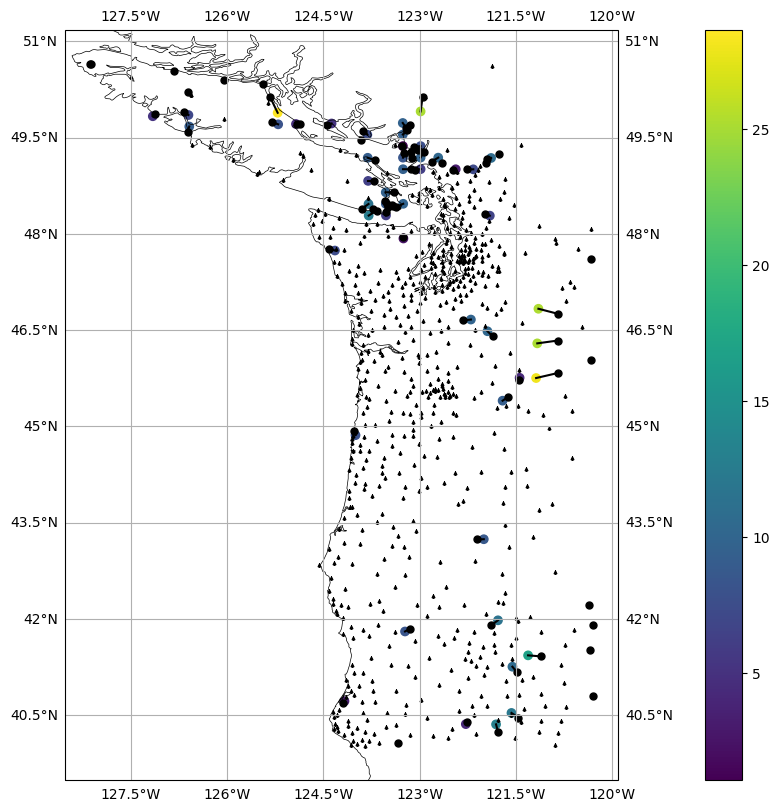

In [24]:
fig = plt.figure(figsize=[8,8],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)

# ax.plot(audrey_stas_to_keep.lon, audrey_stas_to_keep.lat, 'b.',label = 'PNSN grid stas to keep')
#ax.plot(needed_from_bgrid.longitude, needed_from_bgrid.latitude,'r.', label = 'Locs needed from BGRID')
ax.plot(prod_sim_stas.longitude,prod_sim_stas.latitude,'k^',markersize=2)
ax.plot([b[0] for b in bgrid_need_loc],[b[1] for b in bgrid_need_loc],'k.',markersize=10)
c = ax.scatter(bgrid_added_stations.lon, bgrid_added_stations.lat, c = bgrid_added_stations.bgrid_dist)
for i in range(len(bgrid_added_stations)):
    ax.plot([bgrid_added_stations.iloc[i].lon,bgrid_added_stations.iloc[i].bgrid_real_lon],[bgrid_added_stations.iloc[i].lat,bgrid_added_stations.iloc[i].bgrid_real_lat],'k-')
# ax.legend()
gl = ax.gridlines(draw_labels=True) 
plt.colorbar(c)

In [25]:
bgrid_added_stations = bgrid.iloc[bgrid_need_match_ind]
bgrid_added_stations = bgrid_added_stations.drop_duplicates(subset = ['stn']).reset_index(drop = True)

In [26]:
len(bgrid_added_stations)

49

In [27]:
bgrid_added_stations

# Only get 49 out of 76 desired due to geographic limits of the grid

,stn,lon,lat,rrup(km),PGA_x(g),PGA_y(g),PGV_x(m/s),PGV_y(m/s),PGD_x(m),PGD_y(m),...,SA_0p5s(g),SA_0p75s(g),SA_1p0s(g),SA_1p5s(g),SA_2p0s(g),SA_3p0s(g),SA_4p0s(g),SA_5p0s(g),SA_7p5s(g),SA_10p0s(g)
0,B00203,-121.312,41.434,252.897,0.029539,0.033560,0.210,0.119,0.386,0.287,...,0.0705,0.0558,0.0360,0.0456,0.0457,0.0508,0.0284,0.0348,0.0188,0.0248
1,B00173,-121.556,41.257,228.697,0.038176,0.034013,0.142,0.107,0.309,0.231,...,0.0898,0.0598,0.0356,0.0425,0.0378,0.0526,0.0306,0.0267,0.0200,0.0245
2,B00027,-121.811,40.359,198.260,0.042755,0.044465,0.156,0.097,0.347,0.217,...,0.0967,0.0742,0.0437,0.0307,0.0295,0.0240,0.0232,0.0154,0.0160,0.0218
3,B00253,-123.229,41.806,102.933,0.108763,0.097808,0.191,0.193,0.448,0.358,...,0.2699,0.1579,0.0634,0.0651,0.0441,0.0320,0.0234,0.0228,0.0219,0.0325
4,B00025,-122.282,40.363,158.834,0.058439,0.083178,0.235,0.088,0.439,0.159,...,0.1732,0.0825,0.0610,0.0567,0.0669,0.0400,0.0314,0.0187,0.0164,0.0299
5,B01517,-126.590,49.672,37.139,0.141818,0.190408,0.215,0.335,1.294,1.344,...,0.2650,0.1384,0.0833,0.0690,0.0621,0.0383,0.0345,0.0342,0.0350,0.0257
6,B01498,-123.816,49.544,163.423,0.065993,0.074697,0.086,0.144,0.117,0.172,...,0.1359,0.1008,0.1054,0.0713,0.0593,0.0301,0.0173,0.0107,0.0107,0.0078
7,B01546,-126.603,49.851,48.469,0.123122,0.111255,0.205,0.287,1.029,1.075,...,0.1781,0.1122,0.0682,0.0440,0.0345,0.0193,0.0206,0.0261,0.0325,0.0251
8,B01529,-123.264,49.727,205.336,0.055529,0.040901,0.078,0.084,0.094,0.172,...,0.1086,0.0824,0.0513,0.0615,0.0396,0.0245,0.0155,0.0124,0.0096,0.0061
9,B00057,-121.571,40.537,216.845,0.037238,0.036554,0.142,0.088,0.359,0.238,...,0.0864,0.0584,0.0335,0.0341,0.0291,0.0269,0.0269,0.0204,0.0205,0.0182


# Great. Now I need to make miniseeds following the list of stations from the PNSN, offshore, and BGRID lists I've developed

In [28]:
write_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/offshore_mseeds/'
write_path = '/Users/zoekrauss/shakealert_8Hz/'

# PNSN grid
pnsn_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/audrey_broadband_pnsngrid/'
# Offshore grid
offshore_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/audrey_offshore_stations/'
# BGRID
bgrid_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/audrey_broadband_bgrid/'

scenarios=(
"buried-locking-mur13-deep",
"buried-locking-mur13-middle",
"buried-locking-mur13-shallow",
"buried-locking-skl16-deep",
"buried-locking-skl16-middle",
"buried-locking-skl16-shallow",
"buried-locking-str10-deep",
"buried-locking-str10-middle",
"buried-locking-str10-shallow",
"buried-random-mur13-deep",
"buried-random-mur13-middle",
"buried-random-mur13-shallow",
"buried-random-skl16-deep",
"buried-random-skl16-middle",
"buried-random-skl16-shallow",
"buried-random-str10-deep",
"buried-random-str10-middle",
"buried-random-str10-shallow",
"ft-locking-mur13-deep",
"ft-locking-mur13-middle",
"ft-locking-mur13-shallow",
"ft-locking-skl16-deep",
"ft-locking-skl16-middle",
"ft-locking-skl16-shallow",
"ft-locking-str10-deep",
"ft-locking-str10-middle",
"ft-locking-str10-shallow",
"ft-random-mur13-deep",
"ft-random-mur13-middle",
"ft-random-mur13-shallow",
"ft-random-skl16-deep",
"ft-random-skl16-middle",
"ft-random-skl16-shallow",
"ft-random-str10-deep",
"ft-random-str10-middle",
"ft-random-str10-shallow",
)

In [29]:
import obspyh5
scenario = scenarios[0]
offshore_st = obspyh5.readh5(offshore_path+'OFFSHORE_'+scenario+'_BB.h5')

In [30]:
# Remove duplicates based on trace metadata
def drop_duplicates_by_stats(stream):
    """
    Returns a new Stream containing only unique traces based on stats.
    """
    seen_ids = set()
    unique_stream = Stream()
    for trace in stream:
        trace_id = trace.get_id()
        if trace_id not in seen_ids:
            unique_stream.append(trace)
            seen_ids.add(trace_id)
    return unique_stream

In [31]:
# Stations you want to downsample
downsample_codes = ['HYSB1','HYS14','NCBC','NC89','CZSB1','CZMC1','BACND','CZSD1','CZSC1','BACME','CQS64','NC27','CBC27']
# downsample_codes = []

In [90]:
# Assemble a stream from all h5s: Audrey PNSN stations (the ones we're keeping) and the new BGRID stations

save_folder = 'cascadia_obs_downsampled_mseeds/'
for scenario in scenarios:

    print(scenario)
    tr_codes = []
    
    # PNSN stations - only keep the stations in audrey_stas_to_keep
    pnsn_st = obspyh5.readh5(pnsn_path+'PNSN_broadband_' + scenario + '.h5')
    pnsn_st = pnsn_st.sort(['station'])
    # print(pnsn_st)
    pnsn_keep_st = Stream()
    for s in range(len(audrey_stas_to_keep)):
        sta = audrey_stas_to_keep.stn[s]
        tr = pnsn_st.select(station = sta)
        pnsn_keep_st += tr

    #### ONLY ADD THIS BLOCK IF YOU WANT OFFSHORE STATIONS #####
    # Offshore grid - we keep ALL of these stations
    offshore_st = obspyh5.readh5(offshore_path+'OFFSHORE_'+scenario+'_BB.h5')
    offshore_st = offshore_st.sort(['station'])
    ################################################################

    # BGRID - only keep the ones we want to add
    bgrid_st = obspyh5.readh5(bgrid_path+'BGRID_broadband_' + scenario + '.h5')
    bgrid_st = bgrid_st.sort(['station'])
    # print(bgrid_st)
    bgrid_keep_st = Stream()
    for b in range(len(bgrid_added_stations)):
        sta = bgrid_added_stations.stn[b]
        tr = bgrid_st.select(station = sta)
        bgrid_keep_st += tr

    print('Keeping lengths:')
    print(len(pnsn_keep_st), len(bgrid_keep_st))
    
    # Combine streams
    comb_st = pnsn_keep_st + bgrid_keep_st + offshore_st
    
    # Drop the duplicates (this shouldn't actually be necessary if I've done everything right!)
    st_unique = drop_duplicates_by_stats(comb_st)
    print('Combined and unique lengths:')
    print(len(comb_st), len(st_unique))
    
    st = st_unique.copy()

    # Change channel name from one character to three (copying Mika's format) because ShakeAlert requires it
    for tr in st:
        
        if tr.stats.channel == 'N':
            tr.stats.channel = 'ENN'
        elif tr.stats.channel == 'E':
            tr.stats.channel = 'ENE'
        elif tr.stats.channel == 'Z':
            tr.stats.channel = 'ENZ'
    
        sta_name = tr.stats.station
        if len(sta_name) > 5:
            new_sta_name = sta_name[1:]
            tr.stats.station = new_sta_name
    
        # New filename based on net, sta, loc, chan
        mseed_name = tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.location + '.' + tr.stats.channel + '.mseed'

        # Add 60 s padding to the start of the waveform
        pad_seconds = 60
        pad_samples = int(pad_seconds * tr.stats.sampling_rate)
        pad_data = np.zeros(pad_samples, dtype = tr.data.dtype)
        tr.data = np.concatenate([pad_data, tr.data])
        # Update metadata
        tr.stats.npts = len(tr.data)
    
        # Multiply data by 10**5 to be able to convert to integers without losing resolution
        tr.data = tr.data * 10**5
    
        # Add some noise to avoid divide by zero STA/LTA issue (same code as Mika)
        tr.data = tr.data + np.random.normal(0, 100, len(tr))

        # Downsample if desired
        if sta_name in downsample_codes:

            st2 = offshore_st.copy()
            t1 = tr.stats.starttime
            t2 = tr.stats.endtime
            tr.trim(t1-5,t2+5,fill_value=np.int32(np.mean(tr.data)),pad=True) # pad ends so we can cut off edge effects
            tr.resample(8.0,no_filter=False)
            tr.trim(t1,t2)

        else:
            # 10 Hz acausal/zerophase low pass filter (above 10 Hz not trustworthy)
            tr.data = lowpass(tr.data, freq = 10, df = tr.stats.sampling_rate, zerophase = True)        
        
        # Convert to int 
        tr.data = tr.data.astype(int)
    
        # Make writing folder and write trace
        if os.path.isdir(write_path + save_folder + scenario):
            pass
        else:
            os.makedirs(write_path + save_folder + scenario)
    
        # Assuming 'trace' is your ObsPy Trace object with int64 data
        if tr.data.dtype == np.int64:
            tr.data = tr.data.astype(np.int32)
    
        try:
            tr.write(write_path + save_folder + scenario + '/' + mseed_name, format = 'MSEED')
            tr_codes.append(tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.channel)

            # Duplicate WOSB and WSLR since there are multiple instruments there
            if tr.stats.station in ['WOSB', 'WSLR']:
                tr.stats.station = tr.stats.station + '2'
                mseed_name = tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.location + '.' + tr.stats.channel + '.mseed'
                tr.write(write_path + save_folder + scenario + '/' + mseed_name, format = 'MSEED')
                tr_codes.append(tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.channel)
            
        except:
            print(tr)

    # print('Traces saved (should be comb/uni length + 2 stations * 3 channels each for double WOSB and WSLR):')
    # print(len(tr_codes))
    # print('')

buried-locking-mur13-deep
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-mur13-middle
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-mur13-shallow
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-skl16-deep
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-skl16-middle
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-skl16-shallow
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-str10-deep
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-str10-middle
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-locking-str10-shallow
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-random-mur13-deep
Keeping lengths:
1932 147
Combined and unique lengths:
2094 2094
buried-random-mur13-middle
Keeping lengths:
1932 147
Combined and unique len

## Write the chanfile for these miniseeds

In [45]:
# Seismic PNSN 
# Station file from Audrey's database for PNSN locations
pnsn_station_txt = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/replays/PNSN_station_locations.txt', delimiter = ' ')
pnsn_keep_stas = pnsn_station_txt[pnsn_station_txt['station'].isin(audrey_stas_to_keep.stn.values)].reset_index(drop = True)


# Add the extra WOSB and WSLR
mask = pnsn_keep_stas['station'].isin(['WOSB', 'WSLR'])
dupes = pnsn_keep_stas.loc[mask].copy()
dupes['station'] = dupes['station'] + '2'
pnsn_keep_stas = pd.concat([pnsn_keep_stas, dupes], ignore_index=True)

print(len(pnsn_keep_stas) == len(audrey_stas_to_keep)+2) # Adding two for duplicated stations

# Seismic BGRID
# Station file from Audrey's database for BGRID locations
bgrid_station_txt = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/replays/BGRID_station_locations.txt', delimiter = ' ')
bgrid_keep_stas = bgrid_station_txt[bgrid_station_txt['station'].isin(bgrid_added_stations.stn.values)].reset_index(drop = True)
print(len(bgrid_keep_stas) == len(bgrid_added_stations))


##### REMOVE BELOW IF OFFSHORE IS NOT USED ######
# Manually add the new offshore sites from Audrey!
offshore_networks=['CZ']*5
offshore_stations=['CZSB1','CZMC1','BACND','CZSD1','CZSC1']
# offshore_latitude=[44.481,44.637,48.34594,44.691,44.364]
# offshore_longitude=[-125.148,-124.306,-126.158,-124.457,-124.961]
# CORRECTION - the locations from Audrey's grid are slightly different
offshore_longitude = [-125.15054,-124.97035,-124.45147,-124.29885,-126.1452]
offshore_latitude = [44.48777,44.36498,44.69685,44.64468,48.35285]
offshore_elevation = [0.0]*5
offshore_stas = pd.DataFrame({'station':offshore_stations,'network':offshore_networks,'longitude':offshore_longitude,'latitude':offshore_latitude,'elevation(m)':offshore_elevation})

# Combine the dfs into one station df
comb_stas = pd.concat([pnsn_keep_stas, bgrid_keep_stas,offshore_stas]).sort_values(by = ['network', 'station']).reset_index(drop = True)
# print(len(comb_stas)*3 == len(tr_codes))
comb_stas

True
True


,station,network,longitude,latitude,elevation(m)
0,BAKR,BK,-122.492261,40.280351,0.0
1,BIGV,BK,-121.227690,41.094390,0.0
2,BJES,BK,-123.879960,40.543620,0.0
3,BLAS,BK,-123.532480,40.322700,0.0
4,BRIC,BK,-123.896500,40.112230,0.0
...,...,...,...,...,...
695,WYNO,UW,-123.612960,47.433920,0.0
696,YACH,UW,-124.096600,44.315000,0.0
697,YACT,UW,-122.419300,45.932500,0.0
698,YELM,UW,-122.590810,46.940160,0.0


In [46]:
# Sampling rates!!!

comb_stas['samplerate'] = '50.0'
mask = comb_stas['station'].isin(downsample_codes)
comb_stas.loc[mask, 'samplerate'] = '8.0'
print(comb_stas.index[mask].tolist())

[145, 146, 147, 148, 149, 208, 210, 211, 212, 213, 214, 218, 219]


In [47]:
# HERE IF YOU WANT TO EXCLUDE THE DOWNSAMPLED STATIONS!!!!!
print(len(comb_stas))
exclude_inds = comb_stas.index[mask].tolist()
comb_stas = comb_stas.drop(exclude_inds)
print(len(comb_stas))

700
687


In [40]:
comb_stas.iloc[145:155]

,station,network,longitude,latitude,elevation(m),samplerate
150,COR,IU,-123.304600,44.585500,0.0,50.0
151,KBU,NC,-123.853200,40.245530,0.0,50.0
152,KCO,NC,-124.265984,40.256748,0.0,50.0
153,KCR,NC,-123.820641,40.426441,0.0,50.0
154,KCSB,NC,-123.513998,40.538363,0.0,50.0
155,KCT,NC,-124.337486,40.475567,0.0,50.0
156,KFB,NC,-123.795410,41.728020,0.0,50.0
157,KHBB,NC,-123.219658,40.659901,0.0,50.0
158,KHMB,NC,-123.732590,40.874748,0.0,50.0
159,KMPB,NC,-124.120758,40.417194,0.0,50.0


In [48]:
# Reformat to fit ShakeAlert .dat requirements

with pd.option_context('mode.chained_assignment', None):
    remake = comb_stas.copy()
    repeat = pd.concat([remake] * 3, ignore_index = True)
    repeat = repeat.sort_values(by = ['station']).reset_index(drop = True)
    channels = ['ENE', 'ENN', 'ENZ'] * len(remake)
    locations = ['--'] * len(repeat)
    samplerates = ['50.0'] * len(repeat)
    gains = ['100000'] * len(repeat)
    units = ['counts/(cm/sec2)'] * len(repeat)
    repeat['channel'] = channels
    repeat['location'] = locations
    # repeat['samplerate'] = samplerates
    repeat['gain'] = gains
    repeat['units'] = units
    repeat = repeat.sort_values(by = ['station', 'channel']).reset_index(drop = True)
    repeat = repeat.rename(columns = {'elevation(m)': 'elevation'})
    station_dat = repeat[['network', 'station', 'location', 'channel', 'latitude', 'longitude', 'elevation', 'samplerate', 'gain', 'units']]
    
    # Rename stations with 6 chars by removing the first one. Need to rename mseed file names too if you made them without fixing this
    renamed_dat = station_dat.copy()
    for j in range(len(renamed_dat)):
        sta = renamed_dat['station'][j]
        if len(sta) > 5:
            # print(sta)
            new_name = sta[1:]
            # print(new_name)
            renamed_dat['station'][j] = new_name
    
seismic_control_dat = renamed_dat

In [49]:
# Check to make sure that the samplerate column looks correct
mask = seismic_control_dat['station'].isin(downsample_codes)
print(seismic_control_dat.index[mask].tolist())
seismic_control_dat.iloc[300:315]

[]


,network,station,location,channel,latitude,longitude,elevation,samplerate,gain,units
300,BK,BAKR,--,ENE,40.280351,-122.492261,0.0,50.0,100000,counts/(cm/sec2)
301,BK,BAKR,--,ENN,40.280351,-122.492261,0.0,50.0,100000,counts/(cm/sec2)
302,BK,BAKR,--,ENZ,40.280351,-122.492261,0.0,50.0,100000,counts/(cm/sec2)
303,NV,BAMF,--,ENE,48.835330,-125.135140,0.0,50.0,100000,counts/(cm/sec2)
304,NV,BAMF,--,ENN,48.835330,-125.135140,0.0,50.0,100000,counts/(cm/sec2)
305,NV,BAMF,--,ENZ,48.835330,-125.135140,0.0,50.0,100000,counts/(cm/sec2)
306,UW,BAND,--,ENE,43.090300,-124.409300,0.0,50.0,100000,counts/(cm/sec2)
307,UW,BAND,--,ENN,43.090300,-124.409300,0.0,50.0,100000,counts/(cm/sec2)
308,UW,BAND,--,ENZ,43.090300,-124.409300,0.0,50.0,100000,counts/(cm/sec2)
309,UO,BANKS,--,ENE,45.624450,-123.110340,0.0,50.0,100000,counts/(cm/sec2)


In [50]:
# Save seismic .dat for replays!
seismic_control_dat.to_csv('cascadia_obs_downsampled_mseeds/cascadia_obs_excluded_mseeds.dat', sep = '\t', index = False, header = False)

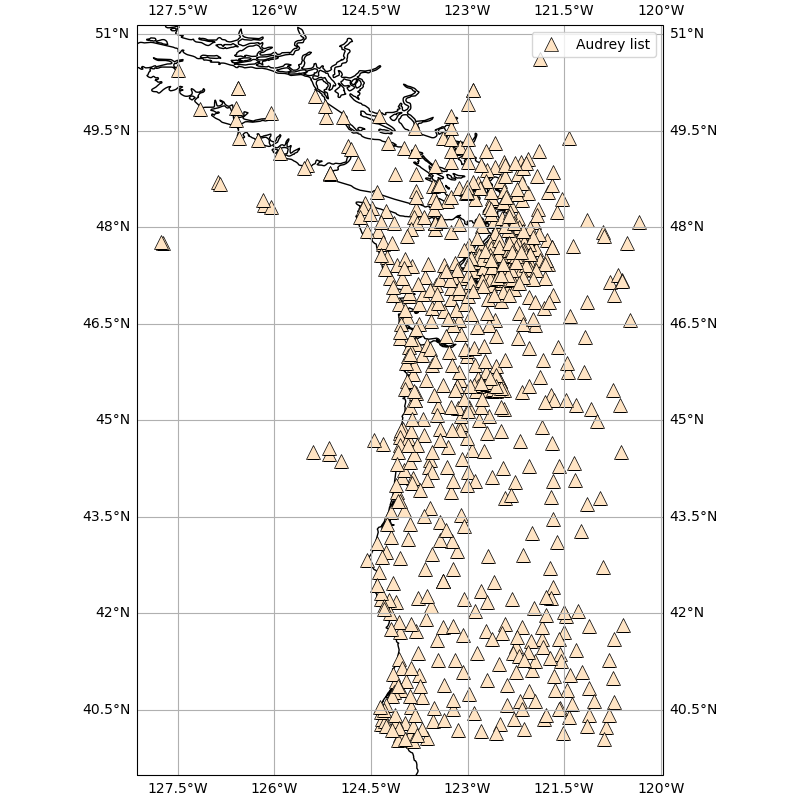

In [46]:
%matplotlib widget

fig = plt.figure(figsize=[8,8],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()


# From PNSN grid
# ax.plot(pnsn_station_df['lon'],pnsn_station_df['lat'],'^',markersize=15,color='bisque',markeredgecolor='k',markeredgewidth=0.5,label='Audrey list')
ax.plot(comb_stas['longitude'],comb_stas['latitude'],'^',markersize=10,color='bisque',markeredgecolor='k',markeredgewidth=0.5,label='Audrey list')
# ax.plot(stations1_lon,stations1_lat,'^',markersize=6,color='brown',label='Mouse/Mika list')
# From BGRID
# ax.plot(bgrid_added_stations['lon'],bgrid_added_stations['lat'],'r^',markersize=2,label='BGRID adds')
# ax.plot(bgrid['lon'],bgrid['lat'],'k.',markersize=2,label='bgrid')


# ax.set_xlim(-128.5,-122)
# ax.set_ylim(40,51)

gl = ax.gridlines(draw_labels=True) 

ax.legend()

In [97]:
# Tar it up, then copy it over to the dev servers
# !tar czf offshore_mseeds/audrey_offshore.tar.gz /Users/zoekrauss/offshore_eew_modeling/replays/offshore_mseeds/seismic_control
!tar czf cascadia_obs_downsampled_mseeds.tar.gz cascadia_obs_downsampled_mseeds
# !scp /Users/zoekrauss/offshore_eew_modeling/replays/audrey_offshore.tar.gz zkrauss@eew-uw-dev1.ess.washington.edu:/home/zkrauss/tnkfiles/audrey_offshore/mseeds

# scp /Users/zoekrauss/shakealert_8hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds.tar.gz zkrauss@eew-uw-dev1.ess.washington.edu:/data/eewdata/miniseeds/downsampled_cascadia


## Save the new list of ShakeAlert stations for making tt grids

In [43]:
prod_sim_stas

,network,station,location,channel,latitude,longitude,elevation
0,BK,BAKR,00,HHE,40.2804,-122.4923,190.1
1,BK,BIGM,00,HHE,40.8865,-123.3621,1068.5
2,BK,BIGV,00,HHE,41.0944,-121.2277,1484.4
3,BK,BJES,00,HHE,40.5436,-123.8800,1047.4
4,BK,BLAS,00,HHE,40.3227,-123.5325,1678.0
...,...,...,...,...,...,...,...
695,UW,WYNO,--,ENE,47.4339,-123.6130,935.4
696,UW,YACH,--,HNE,44.3150,-124.0966,217.0
697,UW,YACT,--,ENE,45.9325,-122.4193,211.2
698,UW,YELM,--,ENE,46.9402,-122.5908,102.9


In [70]:
prod_sim_stas.to_csv('/Users/zoekrauss/offshore_eew_modeling/location/tt_grids/shakealert_stations_sep2025.dat', sep = '\t', index = False, header = False)